# Multi-modal RAG

```
PDF ──▶ 추출(텍스트·표·이미지) ──▶ 요약(LLM/VLM) ──▶ 요약으로 검색 ──▶ 원본으로 답변
         src/extract.py           src/summarize.py     src/retriever.py
```

> 커널: **Python (multimodal-rag)** (`.venv`) 를 선택하세요. 전역 Python 에는 `unstructured` 가 없습니다.

## 0. 환경 검증

In [ ]:
import sys
from pathlib import Path

# 노트북이 notebooks/ 에서 실행돼도 src 패키지를 찾을 수 있게 프로젝트 루트를 경로에 추가
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.settings import DATA_DIR, FIGURES_DIR, cached, check_env

check_env()

Python: 3.11.18
가상환경 경로: /Users/zionhann/Development/hyundai_ai_campus/part2/multimodal-rag/.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK

API 키     : sk-proj...Vq0A


## 1. 데이터 추출

> ⏱️ 처음 실행 시 2~3분. 이후에는 `data/processed/extracted.pkl` 캐시를 씁니다.
> 다른 PDF 로 바꾸면 `data/processed/*.pkl` 과 `data/figures/` 를 지우고 다시 실행하세요.

In [2]:
from src.extract import extract

PDF_PATH = DATA_DIR / "sample_text.pdf"

extracted = cached("extracted.pkl", lambda: extract(PDF_PATH, FIGURES_DIR))

print("텍스트 블록 수:", len(extracted["texts"]))
print("표 블록 수    :", len(extracted["tables"]))
print("분할 후 블록 수:", len(extracted["texts_2k_token"]))

캐시 사용: /Users/zionhann/Development/hyundai_ai_campus/part2/multimodal-rag/data/processed/extracted.pkl
텍스트 블록 수: 12
표 블록 수    : 0
분할 후 블록 수: 27


## 2. 요약 생성

> 💸 API 를 호출합니다. 결과는 `data/processed/summaries.pkl` 에 캐시되어 **한 번만** 과금됩니다.

In [3]:
from src.summarize import summarize_all

summaries = cached("summaries.pkl", lambda: summarize_all(extracted, FIGURES_DIR))

print(f"텍스트: 원본 {len(extracted['texts_2k_token'])} / 요약 {len(summaries['text_summaries'])}")
print(f"표    : 원본 {len(extracted['tables'])} / 요약 {len(summaries['table_summaries'])}")
print(f"이미지: 원본 {len(summaries['img_base64_list'])} / 요약 {len(summaries['image_summaries'])}")

저장 완료: /Users/zionhann/Development/hyundai_ai_campus/part2/multimodal-rag/data/processed/summaries.pkl
텍스트: 원본 27 / 요약 27
표    : 원본 0 / 요약 0
이미지: 원본 53 / 요약 53


## 3. 다중 벡터 검색기 (요약 → Chroma, 원본 → InMemoryStore)

In [4]:
from src.retriever import create_multi_vector_retriever

retriever = create_multi_vector_retriever(
    summaries["text_summaries"], extracted["texts_2k_token"],
    summaries["table_summaries"], extracted["tables"],
    summaries["image_summaries"], summaries["img_base64_list"],
)
print(f"색인 완료: 요약 {len(retriever.vectorstore.get()['ids'])}건")

색인 완료: 요약 80건


## 4. 검색 테스트

그래프나 표를 봐야만 답할 수 있는 질문을 넣으세요.

이미지 1건 / 텍스트 3건
- 2) 1900~2020년까지 28개국 포퓰리즘 정권을 분석한 결과. Manuel Funke, Christoph Trebesch, Moritz Schularick, The Economic Consequences of 
- AI 버블에 대한 우려가 제기되고 있으나, AI는 단기 적 과열을 넘어 미래의 기술 혁신과 경제 성장을 이 끌 성장동력으로 발전할 가능성이 큼  7. 부상하는 디지털  자산시장  디지털 자산시장이 실물·금융자산 토큰
- ￭ 2026년 글로벌 트렌드  ① 포퓰리즘(populism)의 시대  세계적인 포퓰리즘 정부의 확산은 해당 국가의 경제 및 사회 환경의 급변은 물론 주변국과의 외교적 군사적 마찰 증대 등 다양한 부작용을 유발할 수 


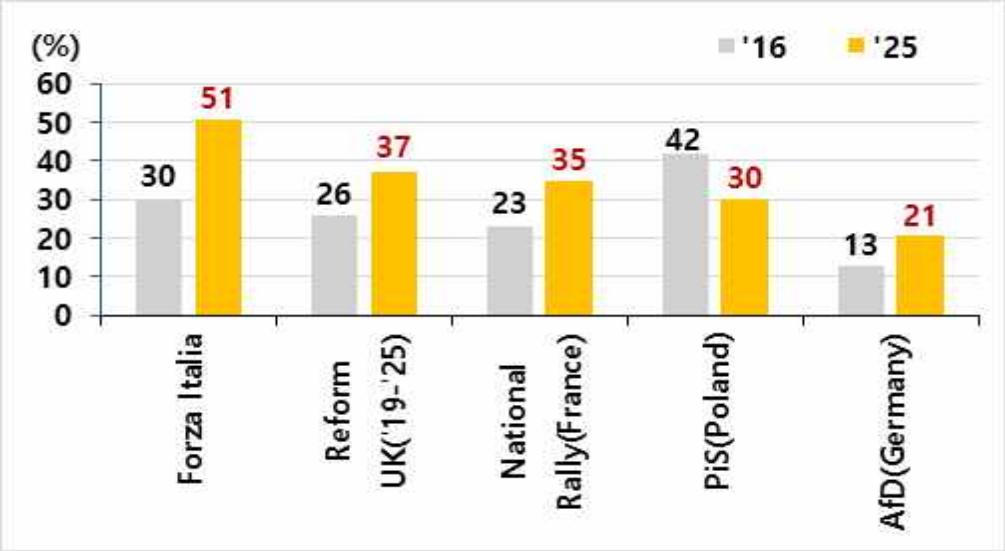

In [5]:
import base64
from IPython.display import Image, display
from src.retriever import split_image_text_types

query = "폴란드 법과정의당(PiS)의 지지율은 2016년 이후 어떻게 변했나?"

split = split_image_text_types(retriever.invoke(query))
print(f"이미지 {len(split['images'])}건 / 텍스트 {len(split['texts'])}건")

for t in split["texts"]:
    print("-", t[:120].replace("\n", " "))
for img in split["images"]:
    display(Image(data=base64.b64decode(img), width=400))

## 5. 멀티모달 RAG 질의

In [6]:
import time
from src.retriever import multi_modal_rag_chain

chain = multi_modal_rag_chain(retriever)

start = time.time()
answer = chain.invoke(query)
print(f"소요 시간: {time.time() - start:.1f}초")
print(f"Q. {query}")
print("-" * 60)
print(answer)

소요 시간: 2.4초
Q. 폴란드 법과정의당(PiS)의 지지율은 2016년 이후 어떻게 변했나?
------------------------------------------------------------
폴란드 법과정의당(PiS)의 지지율은 2016년에 비해 2025년에 상승했습니다. 2016년에는 30%였으나, 2025년에는 42%로 증가했습니다.
